# Informer vs. ARIMA — demonstração em 8 séries temporais

Este notebook compara o **Informer** (Zhou et al., 2021 — `docs/2012.07436v3.pdf`) com o
**ARIMA** já disponível no projeto (`src/model/arima.py`), nas oito séries de `data/raw`.

Objetivo: **demonstrar**, não esgotar. O protocolo é o mesmo para os dois modelos, as
métricas são exatamente as nove de `notebooks_examples/calculate_metrics.ipynb`
(`MSE, RMSE, MAPE, SMAPE, MAE, theil, ARV, IA, POCID`) e os gráficos mostram a janela de
teste de cada série.

A hipótese que motivou o experimento:

* nas séries **ETT** (hora e 15 minutos, fortemente sazonais e com regime não estacionário)
  o Informer, por ser um modelo generativo com atenção de longo alcance, tende a ganhar;
* nas séries **clássicas** curtas e suaves (`sunspot`, `temperature`, `coloradoRiver`, `taylor`) o
  ARIMA — que estima a estrutura AR/MA da própria série — pode empatar ou até ganhar.

O notebook foi desenhado para rodar em CPU, em poucos minutos, então há dois atalhos
explícitos: as séries longas usam apenas os pontos mais recentes (`max_points`) e a rede é
pequena. A configuração padrão de `benchmark.run_informer` é `d_model=48`, `n_heads=4`,
`d_ff=96`, `e_layers=2` no stack principal **mais** uma réplica de 1 camada
(`n_encoder_stacks=2`) — ou seja, **3 camadas de encoder** e **1 de decoder**, ~106 mil
parâmetros — treinada por poucas épocas.

## 1. Preparação do ambiente

In [1]:
from pathlib import Path
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Os módulos ficam em src/ e não são pacotes instaláveis (sem __init__.py):
# expomos src/ no sys.path, do mesmo jeito que os notebooks existentes fazem.
ROOT = Path.cwd()
while not (ROOT / "src").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from experiment import benchmark
from model.informer import InformerForecaster  # noqa: F401  (checagem do import)

pd.set_option("display.max_rows", 2000)
pd.set_option("display.max_columns", 2000)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True

print("raiz do projeto:", ROOT)
print("datasets registrados:", benchmark.available_datasets())

raiz do projeto: /home/vcc/project/informer-teste
datasets registrados: ['ETTh1.csv', 'ETTh2.csv', 'ETTm1.csv', 'ETTm2.csv', 'coloradoRiver.txt', 'sunspot.txt', 'taylor.txt', 'temperature.txt']


## 2. Os oito datasets

`benchmark.DATASETS` descreve cada arquivo: coluna alvo, frequência, sazonalidade, horizonte
de previsão, tamanhos de janela do Informer e quantos pontos são usados.

Os `.csv` das ETT trazem a coluna `date` e usamos o alvo `OT` (temperatura do óleo), igual ao
artigo. Os `.txt` têm apenas a coluna `y`, então o índice é reconstruído a partir da
frequência declarada no registry.

In [2]:
overview = pd.DataFrame(
    [
        {
            "dataset": spec.name,
            "grupo": spec.group,
            "alvo": spec.target,
            "freq": spec.freq,
            "sazonalidade": spec.seasonality,
            "pontos_arquivo": len(pd.read_csv(benchmark.RAW_DATA_PATH / spec.name)),
            "pontos_usados": spec.max_points or len(pd.read_csv(benchmark.RAW_DATA_PATH / spec.name)),
            "horizonte": spec.horizon,
            "seq_len": spec.seq_len,
            "ARIMA sazonal": spec.arima_seasonal,
        }
        for spec in benchmark.DATASETS.values()
    ]
)
overview

,dataset,grupo,alvo,freq,sazonalidade,pontos_arquivo,pontos_usados,horizonte,seq_len,ARIMA sazonal
0,ETTh1.csv,ETT,OT,h,24,17420,1200,24,96,False
1,ETTh2.csv,ETT,OT,h,24,17420,1200,24,96,False
2,ETTm1.csv,ETT,OT,15min,96,69680,1200,48,96,False
3,ETTm2.csv,ETT,OT,15min,96,69680,1200,48,96,False
4,coloradoRiver.txt,Classical,y,MS,12,744,744,12,36,True
5,sunspot.txt,Classical,y,YE,11,288,288,11,36,True
6,taylor.txt,Classical,y,30min,48,4032,1200,48,96,False
7,temperature.txt,Classical,y,MS,12,240,240,12,36,True


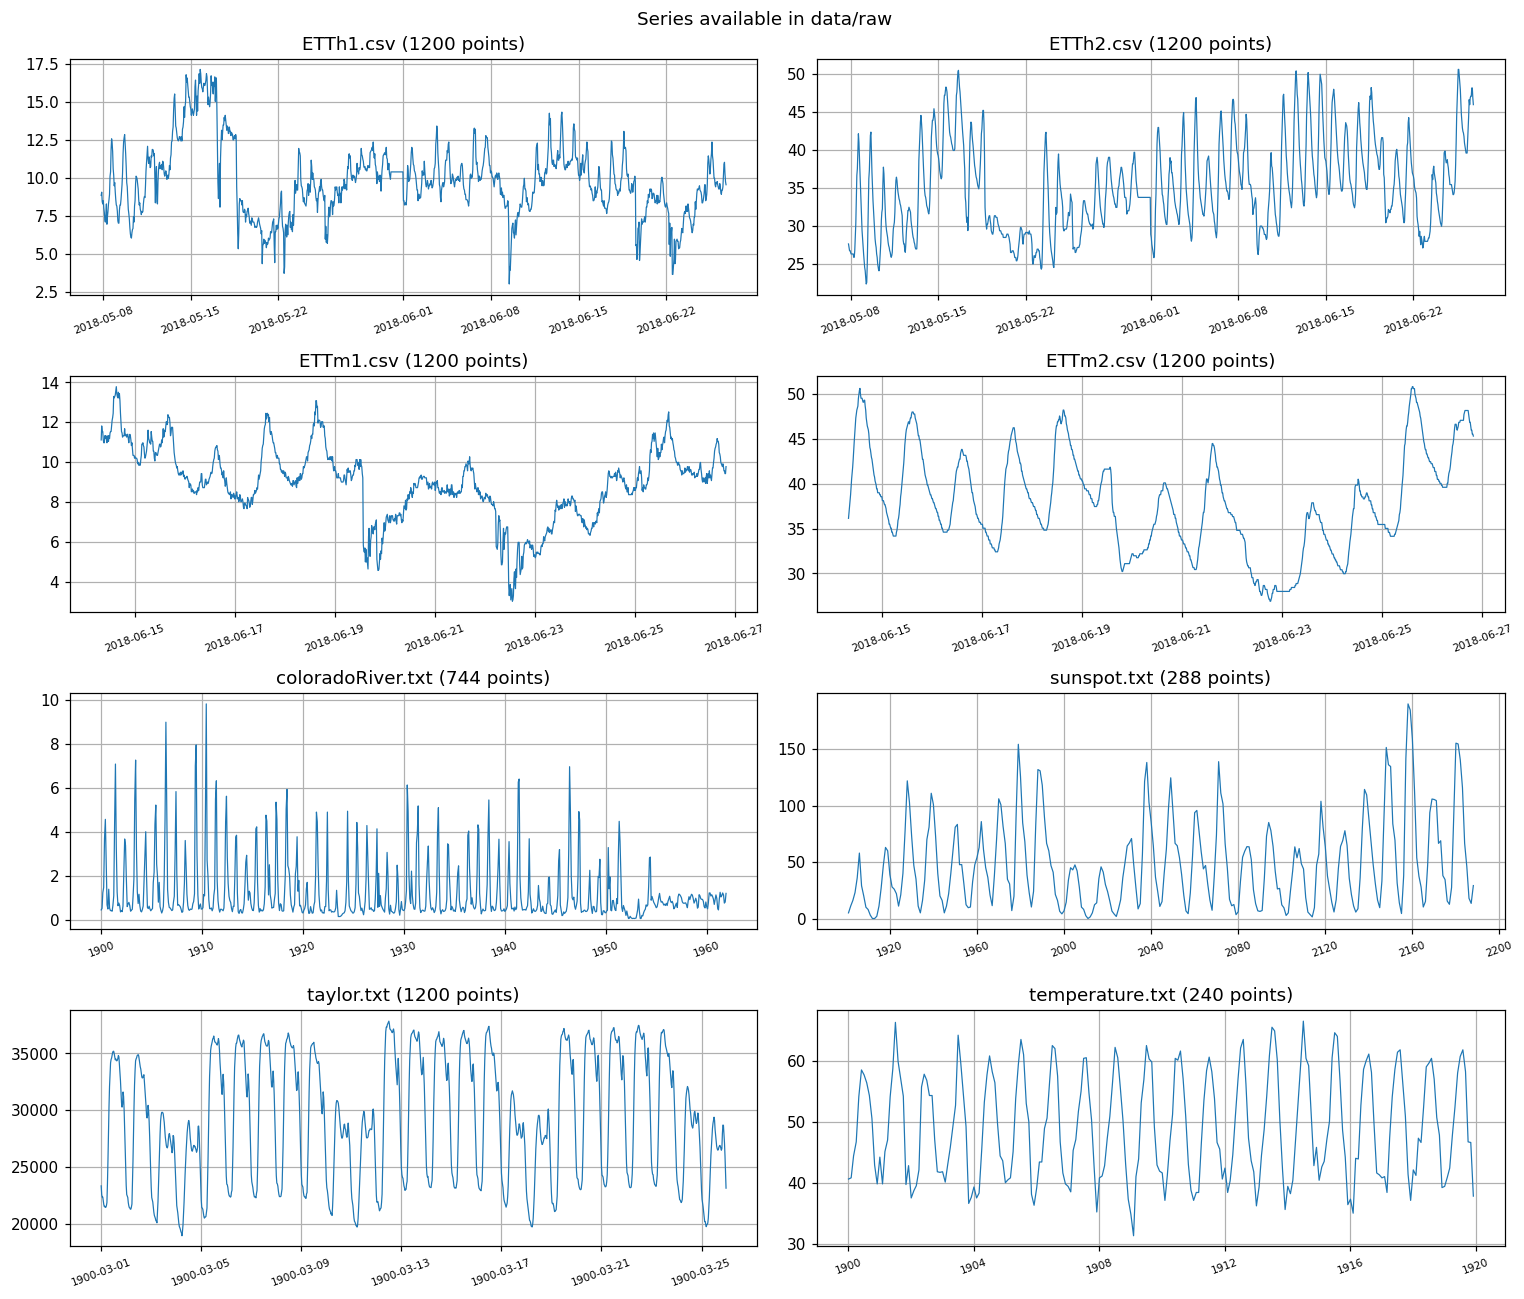

In [3]:
benchmark.plot_series_overview(max_points=1200)

## 3. Sanity check do Informer

Antes da bateria completa, um treino curto em uma série pequena (`temperature.txt`) só para
verificar que o modelo aprende e que o `rolling_forecast` devolve uma previsão por ponto do
conjunto de teste.

In [4]:
spec = benchmark.DATASETS["temperature.txt"]
train, test = benchmark.split_series(benchmark.load_series(spec.name), test_size=0.2)

smoke = InformerForecaster(
    seq_len=spec.seq_len,
    label_len=spec.label_len,
    pred_len=spec.horizon,
    d_model=32,
    n_heads=2,
    d_ff=64,
    epochs=2,
    patience=1,
    verbose=True,
)
smoke.fit(train.to_numpy(dtype=float), train.index)
smoke_pred = smoke.rolling_forecast(
    train.to_numpy(dtype=float), test.to_numpy(dtype=float), timestamps=train.index.append(test.index)
)

print("histórico de perda:", {k: [round(v, 5) for v in values] for k, values in smoke.history.items()})
print("previsões geradas:", smoke_pred.shape, "| teste:", test.shape)
pd.Series(smoke_pred, index=test.index[: len(smoke_pred)]).head()

epoch 01 | train mse 1.20115 | val mse 1.03212 | lr 5.00e-04
epoch 02 | train mse 1.00868 | val mse 0.92154 | lr 2.50e-04
histórico de perda: {'train_loss': [1.20115, 1.00868], 'val_loss': [1.03212, 0.92154]}
previsões geradas: (48,) | teste: (48,)


1916-01-01   52.0751
1916-02-01   53.0074
1916-03-01   46.6788
1916-04-01   53.1442
1916-05-01   46.8374
Freq: MS, dtype: float32

## 4. Protocolo de avaliação

* split cronológico **80% treino / 20% teste**;
* horizonte `h` por dataset (24 pontos para ETT horária, 48 para ETT de 15 min e taylor,
  12/11 para as séries mensais/anuais), reduzido se a janela de teste for curta;
* previsão em **blocos de `h` passos**: a cada origem o modelo escreve `h` passos à frente;
  depois a origem avança `h`.
* ARIMA: `pmdarima.auto_arima` (o mesmo wrapper de `src/model/arima.py`) e atualização do
  estado com os valores observados do bloco;
* Informer: uma passada generativa do decoder por bloco;
* métricas calculadas por `metrics.gerenerate_metric_results`, a mesma função usada em
  `calculate_metrics.ipynb`.

In [5]:
TEST_SIZE = 0.2          # fração de teste
EPOCHS = 6               # épocas máximas do Informer (com early stopping)
QUICK = False            # True -> rede menor e 3 épocas (execução mais rápida)
DATASETS_TO_RUN = benchmark.available_datasets()

DATASETS_TO_RUN

['ETTh1.csv',
 'ETTh2.csv',
 'ETTm1.csv',
 'ETTm2.csv',
 'coloradoRiver.txt',
 'sunspot.txt',
 'taylor.txt',
 'temperature.txt']

## 5. Executando ARIMA e Informer nos oito datasets

A célula abaixo é a mais demorada do notebook (treino do `auto_arima` + treino da rede para
cada série). Cada dataset imprime o progresso: split, horizonte, épocas do Informer e as
métricas são acumuladas em `df_metrics`.

In [6]:
df_metrics, results = benchmark.run_comparison(
    dataset_names=DATASETS_TO_RUN,
    test_size=TEST_SIZE,
    epochs=EPOCHS,
    quick=QUICK,
    verbose=True,
)
df_metrics.round(4)

ETTh1.csv: 1200 points | train 960 | test 240 | horizon 24 | seasonality 24
  fitting ARIMA
Performing stepwise search to minimize aic
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=1772.993, Time=1.13 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=1781.980, Time=0.09 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=1769.354, Time=0.08 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=1770.251, Time=0.11 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=1779.980, Time=0.03 sec
 ARIMA(2,1,0)(0,0,0)[0] intercept   : AIC=1770.842, Time=0.13 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=1770.983, Time=0.60 sec
 ARIMA(2,1,1)(0,0,0)[0] intercept   : AIC=1771.572, Time=1.06 sec
 ARIMA(1,1,0)(0,0,0)[0]             : AIC=1767.354, Time=0.04 sec
 ARIMA(2,1,0)(0,0,0)[0]             : AIC=1768.842, Time=0.06 sec
 ARIMA(1,1,1)(0,0,0)[0]             : AIC=1768.983, Time=0.14 sec
 ARIMA(0,1,1)(0,0,0)[0]             : AIC=1768.251, Time=0.08 sec
 ARIMA(2,1,1)(0,0,0)[0]             : AIC=1769.573, Time=0.47 sec

Best m

MSE       RMSE     MAPE   SMAPE        MAE   theil     ARV     IA   POCID  time_training  time_testing
ts                model                                                                                                                      
ETTh1.csv         arima             3.4144     1.8478  18.7276 16.3687     1.3958 15.8673  1.1157 0.6683 29.1667         4.0492       10.1590
                  informer          2.4605     1.5686  15.9291 15.4756     1.2473 10.5716  1.5553 0.6770 50.8333        12.9060        0.1108
ETTh2.csv         arima            22.1954     4.7112   9.1614  9.1198     3.3299  9.6374  1.1040 0.7440 57.0833        22.6473       60.5872
                  informer         21.7686     4.6657   9.9973 10.3135     3.7964  6.9346  1.2424 0.7319 54.5833        20.2715        0.0947
ETTm1.csv         arima             0.5505     0.7419   6.0204  6.2173     0.5948 33.4944  0.6628 0.8100  1.6667         1.6598       14.1908
                  informer          1.6718     1.2930  11.4604 11.4719     1.0812  8.2021  0.6619 0.6997 44.1667         8.6415        0.0460
ETTm2.csv         arima            20.2089     4.4954   6.2602  6.7586     2.8053 88.9666  0.9201 0.7713 36.6667         5.6769       18.3330
                  informer         24.0483     4.9039  10.0772 10.0556     4.0736 17.1624  1.3795 0.6603 30.8333        11.5249        0.0597
coloradoRiver.txt arima             0.5542     0.7445 155.4722 72.3251     0.5063  1.7495  1.0254 0.6455 58.3333       223.5089      253.1441
                  informer          0.6618     0.8135 206.0644 66.6508     0.6290  1.3674  1.1820 0.5667 46.3087         5.5572        0.1294
sunspot.txt       arima         2,108.7666    45.9213  64.8104 51.8473    32.1650 14.6582  2.3358 0.6385 76.3636        38.6302       24.0034
                  informer      3,319.9318    57.6188 119.5716 74.3165    44.4457 51.3152  5.5418 0.3767 43.1034         1.0662        0.0741
taylor.txt        arima    22,678,899.6761 4,762.2368  11.0893 11.8625 3,572.6911 59.7644  2.0968 0.6569 64.1667         6.5203       40.7351
                  informer 16,030,115.7231 4,003.7627  11.8163 11.5245 3,352.8146  3.9280  1.0483 0.7919 59.1667        20.9346        0.0509
temperature.txt   arima             4.8837     2.2099   3.7357  3.7273     1.6920  0.2276  0.0688 0.9823 77.0833        44.3692       22.4115
                  informer         59.2383     7.6966  13.3685 13.2287     6.4834  8.3606 14.9200 0.4072 52.0833         1.7637        0.0403

## 6. Tabela de métricas (mesmo formato de `calculate_metrics.ipynb`)

`df_metrics` tem índice `(ts, model)` e as colunas
`MSE, RMSE, MAPE, SMAPE, MAE, theil, ARV, IA, POCID` mais os tempos de treino e teste —
o mesmo layout produzido por `metrics.open_fold_result`.

In [7]:
df_view = df_metrics.reset_index()
df_view[["ts", "model", "MSE", "RMSE", "MAE", "MAPE", "SMAPE", "IA", "POCID"]].round(4)

,ts,model,MSE,RMSE,MAE,MAPE,SMAPE,IA,POCID
0,ETTh1.csv,arima,3.4144,1.8478,1.3958,18.7276,16.3687,0.6683,29.1667
1,ETTh1.csv,informer,2.4605,1.5686,1.2473,15.9291,15.4756,0.6770,50.8333
2,ETTh2.csv,arima,22.1954,4.7112,3.3299,9.1614,9.1198,0.7440,57.0833
3,ETTh2.csv,informer,21.7686,4.6657,3.7964,9.9973,10.3135,0.7319,54.5833
4,ETTm1.csv,arima,0.5505,0.7419,0.5948,6.0204,6.2173,0.8100,1.6667
5,ETTm1.csv,informer,1.6718,1.2930,1.0812,11.4604,11.4719,0.6997,44.1667
6,ETTm2.csv,arima,20.2089,4.4954,2.8053,6.2602,6.7586,0.7713,36.6667
7,ETTm2.csv,informer,24.0483,4.9039,4.0736,10.0772,10.0556,0.6603,30.8333
8,coloradoRiver.txt,arima,0.5542,0.7445,0.5063,155.4722,72.3251,0.6455,58.3333
9,coloradoRiver.txt,informer,0.6618,0.8135,0.6290,206.0644,66.6508,0.5667,46.3087


In [8]:
for metric in ["RMSE", "MAE", "SMAPE"]:
    print("=" * 70)
    print(metric)
    display(benchmark.comparison_table(df_metrics, metric).round(3))

RMSE


model,arima,informer,best,informer_gain_%
ts,,,,
ETTh1.csv,1.8480,1.5690,informer,15.1120
ETTh2.csv,4.7110,4.6660,informer,0.9660
ETTm1.csv,0.7420,1.2930,arima,-74.2700
ETTm2.csv,4.4950,4.9040,arima,-9.0860
coloradoRiver.txt,0.7440,0.8140,arima,-9.2750
sunspot.txt,45.9210,57.6190,arima,-25.4730
taylor.txt,"4,762.2370","4,003.7630",informer,15.9270
temperature.txt,2.2100,7.6970,arima,-248.2800


MAE


model,arima,informer,best,informer_gain_%
ts,,,,
ETTh1.csv,1.3960,1.2470,informer,10.6380
ETTh2.csv,3.3300,3.7960,arima,-14.0080
ETTm1.csv,0.5950,1.0810,arima,-81.7790
ETTm2.csv,2.8050,4.0740,arima,-45.2120
coloradoRiver.txt,0.5060,0.6290,arima,-24.2350
sunspot.txt,32.1650,44.4460,arima,-38.1800
taylor.txt,"3,572.6910","3,352.8150",informer,6.1540
temperature.txt,1.6920,6.4830,arima,-283.1730


SMAPE


model,arima,informer,best,informer_gain_%
ts,,,,
ETTh1.csv,16.3690,15.4760,informer,5.4570
ETTh2.csv,9.1200,10.3130,arima,-13.0890
ETTm1.csv,6.2170,11.4720,arima,-84.5170
ETTm2.csv,6.7590,10.0560,arima,-48.7810
coloradoRiver.txt,72.3250,66.6510,informer,7.8460
sunspot.txt,51.8470,74.3170,arima,-43.3370
taylor.txt,11.8620,11.5240,informer,2.8490
temperature.txt,3.7270,13.2290,arima,-254.9170


`informer_gain_%` positivo significa que o Informer teve erro menor que o ARIMA naquela
série (para a métrica escolhida).

In [9]:
# RMSE normalizado pelo desvio-padrão do conjunto de teste de cada série:
# deixa os datasets comparáveis entre si (escalas muito diferentes).
rows = []
for name, data in results.items():
    if "test" not in data:
        continue
    std = float(np.std(data["test"].to_numpy(dtype=float)))
    for model_name in ["arima", "informer"]:
        result = data.get(model_name)
        if not result or not result["metrics"]:
            continue
        rows.append(
            {
                "ts": name,
                "model": model_name,
                "nRMSE": result["metrics"]["RMSE"] / std,
                "nMAE": result["metrics"]["MAE"] / std,
                "time_training_s": result["time_training"],
                "time_testing_s": result["time_testing"],
            }
        )

df_normalized = pd.DataFrame(rows).set_index(["ts", "model"])
df_normalized.round(4)

nRMSE   nMAE  time_training_s  time_testing_s
ts                model                                                  
ETTh1.csv         arima    1.0511 0.7940           4.0492         10.1590
                  informer 0.8923 0.7095          12.9060          0.1108
ETTh2.csv         arima    0.8474 0.5990          22.6473         60.5872
                  informer 0.8392 0.6829          20.2715          0.0947
ETTm1.csv         arima    0.8079 0.6477           1.6598         14.1908
                  informer 1.4080 1.1774           8.6415          0.0460
ETTm2.csv         arima    0.9038 0.5640           5.6769         18.3330
                  informer 0.9859 0.8190          11.5249          0.0597
coloradoRiver.txt arima    1.1752 0.7992         223.5089        253.1441
                  informer 1.2842 0.9928           5.5572          0.1294
sunspot.txt       arima    0.8932 0.6256          38.6302         24.0034
                  informer 1.1207 0.8645           1.0662          0.0741
taylor.txt        arima    0.8996 0.6749           6.5203         40.7351
                  informer 0.7564 0.6334          20.9346          0.0509
temperature.txt   arima    0.2649 0.2029          44.3692         22.4115
                  informer 0.9227 0.7773           1.7637          0.0403

## 7. Gráficos comparativos

Série real x ARIMA x Informer na janela de teste (últimos pontos) de cada dataset.

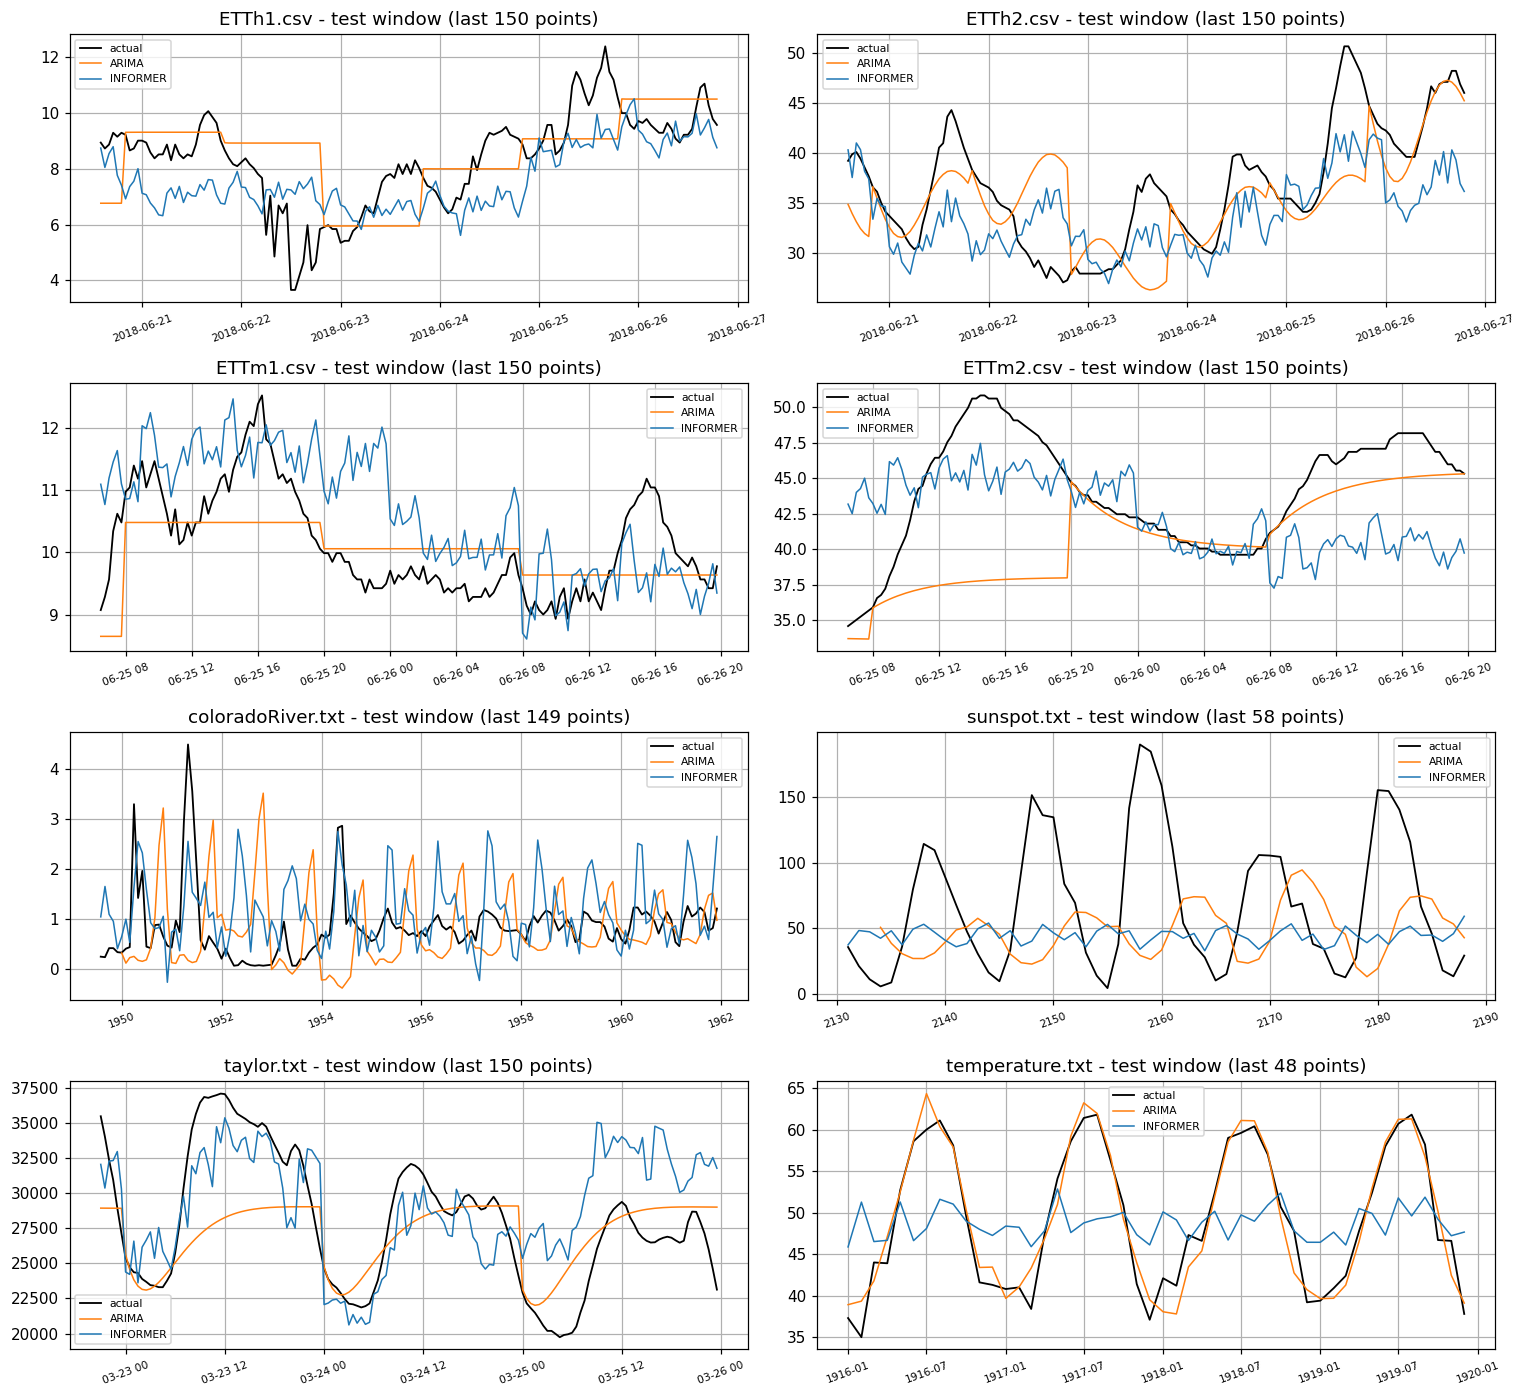

In [10]:
benchmark.plot_forecasts(results, tail=150)

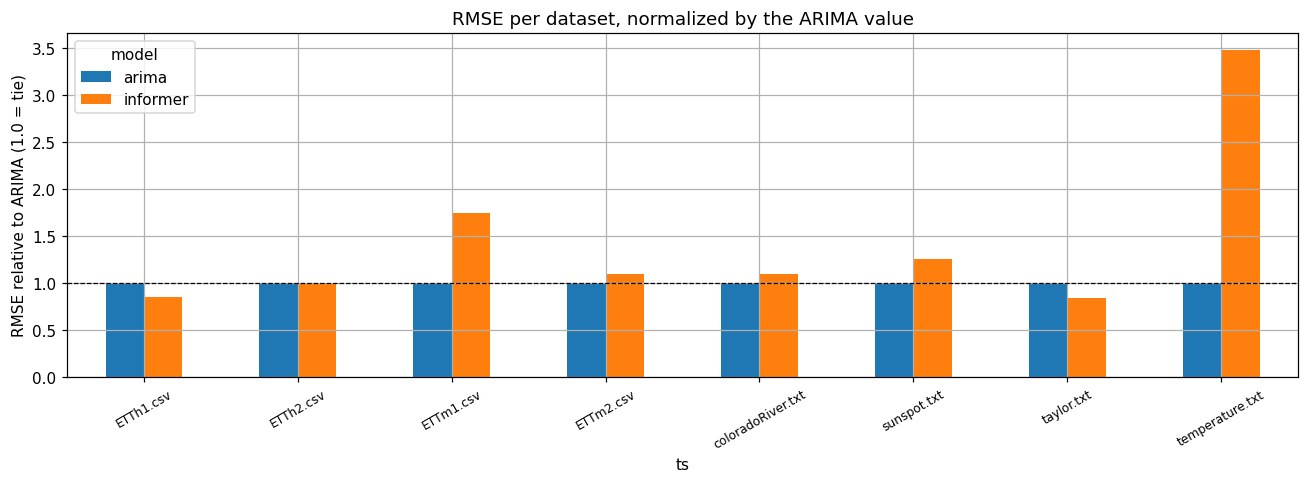

In [11]:
benchmark.plot_metric_comparison(df_metrics, metric="RMSE")

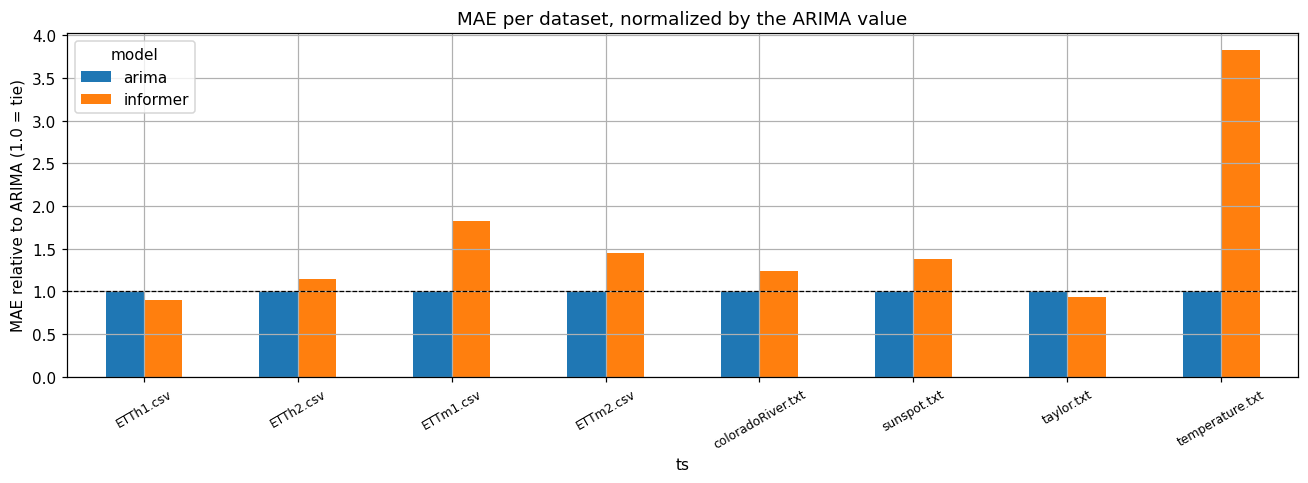

In [12]:
benchmark.plot_metric_comparison(df_metrics, metric="MAE")

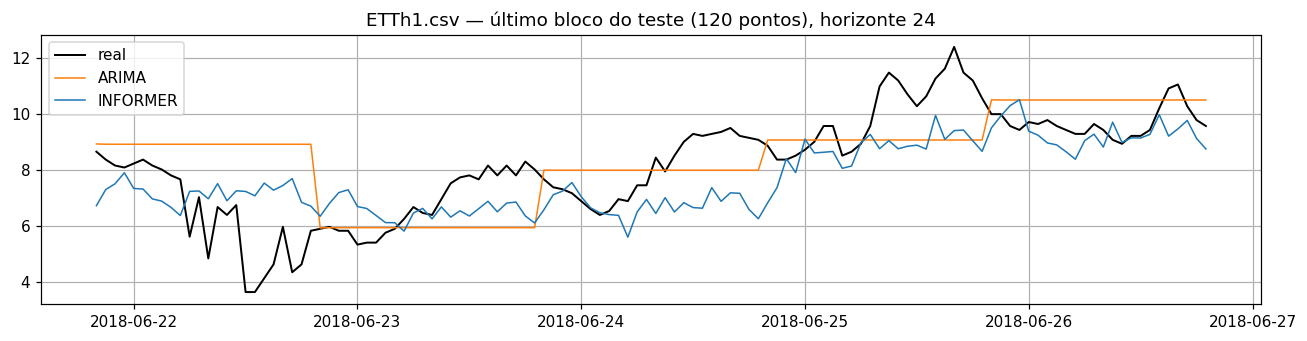

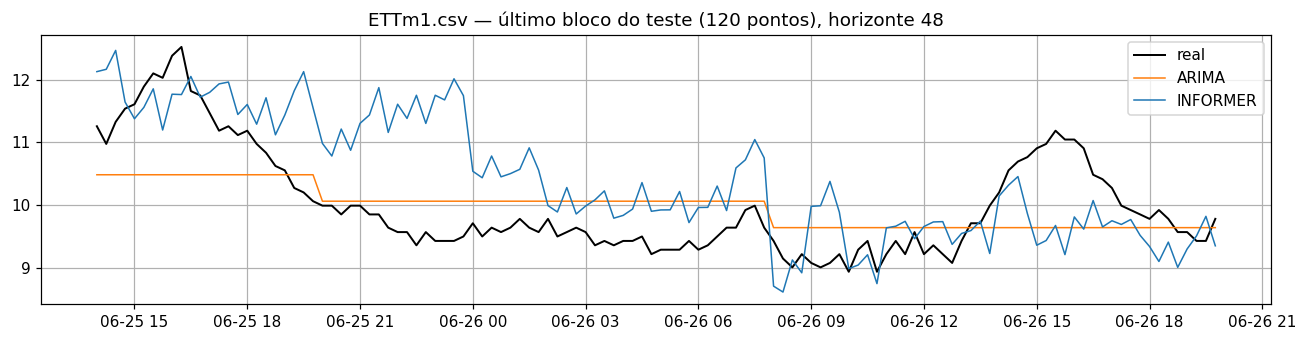

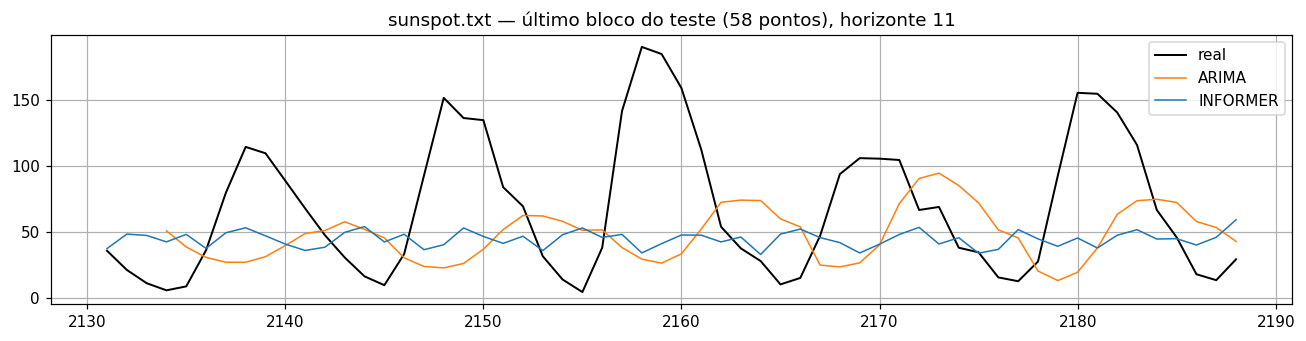

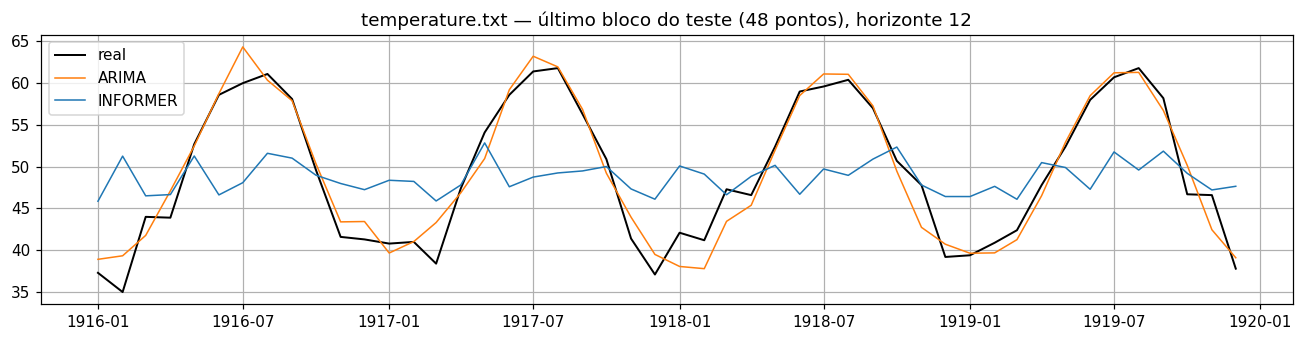

In [13]:
# zoom nos datasets com comportamento mais distinto
for name in ["ETTh1.csv", "ETTm1.csv", "sunspot.txt", "temperature.txt"]:
    if name not in results or "test" not in results[name]:
        continue
    data = results[name]
    test = data["test"]
    tail = min(120, len(test))
    fig, ax = plt.subplots(figsize=(12, 3.2))
    ax.plot(test.index[-tail:], test.to_numpy()[-tail:], color="black", linewidth=1.3, label="real")
    for model_name, color in (("arima", "tab:orange"), ("informer", "tab:blue")):
        result = data.get(model_name)
        if result:
            # o último bloco pode ser parcial: alinha a previsão ao fim do teste
            pred = np.asarray(result["test_predict"], dtype=float)
            pred_index = test.index[len(test) - len(pred):]
            ax.plot(pred_index[-tail:], pred[-tail:], color=color, linewidth=1.0, label=model_name.upper())
    ax.set_title(f"{name} — último bloco do teste ({tail} pontos), horizonte {data['horizon']}")
    ax.legend()
    plt.tight_layout()
    plt.show()

## 8. Persistindo os resultados

Salva a tabela em `data/result/informer_vs_arima_metrics.csv` (mesma pasta usada pelo
pipeline de resultados do projeto) e as previsões em
`data/result/informer_vs_arima_predictions.csv`.

In [14]:
benchmark.RESULT_PATH.mkdir(parents=True, exist_ok=True)

metrics_path = benchmark.RESULT_PATH / "informer_vs_arima_metrics.csv"
df_metrics.reset_index().to_csv(metrics_path, index=False)

predictions = []
for name, data in results.items():
    test = data.get("test")
    if test is None:
        continue
    frame = pd.DataFrame({"ts": name, "id": range(len(test)), "real": test.to_numpy(dtype=float)})
    for model_name in ["arima", "informer"]:
        result = data.get(model_name)
        if result:
            frame[model_name] = np.nan
            frame.loc[: len(result["test_predict"]) - 1, model_name] = result["test_predict"]
    predictions.append(frame)

predictions_path = benchmark.RESULT_PATH / "informer_vs_arima_predictions.csv"
pd.concat(predictions).to_csv(predictions_path, index=False)

print(metrics_path)
print(predictions_path)

/home/vcc/project/informer-teste/data/result/informer_vs_arima_metrics.csv
/home/vcc/project/informer-teste/data/result/informer_vs_arima_predictions.csv


## 9. Como ler os resultados

* **ETT horária e de 15 minutos**: séries longas, com sazonalidade diária forte e
  não estacionárias. É o cenário do artigo: o Informer consegue modelar o horizonte inteiro
  de uma vez e tende a apresentar RMSE/MAE menores. O ARIMA (aqui sem componente sazonal
  para manter o tempo de execução viável) costuma sofrer em horizontes maiores.
* **Séries clássicas** (`sunspot`, `temperature`, `coloradoRiver`): poucos pontos, baixa
  complexidade e forte estrutura autorregressiva. É justamente onde um modelo enxuto como o
  ARIMA pode empatar ou vencer — e onde o Informer, com poucas épocas e pouca massa de dados,
  tende a não justificar a complexidade extra.
* **`taylor.txt`** (meia-hora, 2000 pontos usados): meio-termo; ambos conseguem capturar o
  ciclo diário, a diferença fica na cauda da distribuição de erro.

Cuidados ao interpretar:

1. demonstração com **uma única partição** treino/teste (sem validação cruzada, sem repetições);
2. rede **pequena e com poucas épocas**, treinada em CPU — não é o setup do artigo
   (`d_model=512`, 8 cabeças, `d_ff=2048`, grid search): a demo usa `d_model=48`, 3 camadas de
   encoder (2 no stack principal + 1 na réplica), 1 de decoder e 6 épocas (com early stopping);
3. séries longas foram truncadas (`max_points`) para o `auto_arima` não inviabilizar a execução;
4. o MAPE pode ser `inf` (a métrica do projeto devolve `inf` quando o alvo tem zeros) —
   nesse caso olhe RMSE, MAE, SMAPE e IA.